In [1]:
!pip install -q mlflow optuna

In [2]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


Usando dispositivo: cpu


In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [4]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


In [5]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # Filtrado de Stop Words
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # Normalización (Stemming / Lemmatization)
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)

In [6]:
# Generación de la caché de preprocesamiento para Optuna
print("Precalculando combinaciones de preprocesamiento (esto puede tardar)...")
preprocessed_cache = {}

norm_options = ["none", "stem", "lemmatize"]
sw_options = [False, True]

for norm in norm_options:
    for sw in sw_options:
        print(f"Procesando: remove_stopwords={sw}, normalization={norm}...")
        train_clean = [preprocess_text(doc, remove_stopwords=sw, normalization=norm) for doc in newsgroups_train.data]
        test_clean  = [preprocess_text(doc, remove_stopwords=sw, normalization=norm) for doc in newsgroups_test.data]
        preprocessed_cache[(sw, norm)] = (train_clean, test_clean)

print("¡Caché de textos lista para usar!")

Precalculando combinaciones de preprocesamiento (esto puede tardar)...
Procesando: remove_stopwords=False, normalization=none...
Procesando: remove_stopwords=True, normalization=none...
Procesando: remove_stopwords=False, normalization=stem...
Procesando: remove_stopwords=True, normalization=stem...
Procesando: remove_stopwords=False, normalization=lemmatize...
Procesando: remove_stopwords=True, normalization=lemmatize...
¡Caché de textos lista para usar!


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

def vectorize_data(train_texts, test_texts, ngram_range=(1, 1), max_features=5000, min_df=2):
    """
    Convierte textos crudos en matrices numéricas TF-IDF.
    """
    # 1. Instanciar el vectorizador TF-IDF con los hiperparámetros pasados
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df,
        stop_words='english'  # Elimina palabras comunes en inglés (de, the, is, etc.)
    )

    # 2. Aprender el vocabulario y transformar los datos de entrenamiento
    X_train = vectorizer.fit_transform(train_texts)

    # 3. Transformar los datos de test usando ÚNICAMENTE el vocabulario de train
    # (Importante: usar .transform() y NO .fit_transform() para evitar Data Leakage)
    X_test = vectorizer.transform(test_texts)

    return X_train, X_test, vectorizer


##Modelo DynamicMLP con Regularización

In [8]:
import torch
import torch.nn as nn

class DynamicMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, num_classes, activation_name="relu", dropout_rate=0.0, use_batch_norm=False):
        """
        hidden_dims: lista con neuronas por capa, ej: [256, 128]
        activation_name: 'relu', 'gelu', 'tanh', 'leaky_relu'
        dropout_rate: probabilidad de apagar neuronas (0.0 a 0.5)
        use_batch_norm: True/False para aplicar BatchNorm en cada capa oculta
        """
        super(DynamicMLP, self).__init__()

        activations = {
            "relu": nn.ReLU(),
            "gelu": nn.GELU(),
            "tanh": nn.Tanh(),
            "leaky_relu": nn.LeakyReLU()
        }
        act_layer = activations.get(activation_name.lower(), nn.ReLU())

        layers = []
        prev_dim = input_dim

        for h_dim in hidden_dims:
            # 1. Capa Lineal
            layers.append(nn.Linear(prev_dim, h_dim))

            # 2. Batch Normalization (opcional, estabiliza activaciones)
            if use_batch_norm:
                layers.append(nn.BatchNorm1d(h_dim))

            # 3. Activación
            layers.append(act_layer)

            # 4. Dropout (opcional, apaga neuronas aleatoriamente para evitar overfitting)
            if dropout_rate > 0.0:
                layers.append(nn.Dropout(p=dropout_rate))

            prev_dim = h_dim

        # Capa final de salida (logits)
        layers.append(nn.Linear(prev_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# Sanity check rápido
_dummy = torch.randn(4, 5000)
_model_check = DynamicMLP(input_dim=5000, hidden_dims=[256, 128], num_classes=20, dropout_rate=0.3, use_batch_norm=True)
_out = _model_check(_dummy)
print("Salida del modelo regularizado OK:", _out.shape)

Salida del modelo regularizado OK: torch.Size([4, 20])


In [9]:
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset

def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)

def train_mlp_model(model, train_loader, val_loader, optimizer, epochs, l1_lambda=0.0, l2_lambda=0.0, trial=None, run_name="mlp"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": [],
        "mean_abs_weights": [], "epoch_times": []
    }

    for epoch in range(epochs):
        start_epoch_time = time.time()

        # --- Entrenamiento ---
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            # Penalizaciones L1 y L2 sobre las matrices de pesos (sin incluir biases)
            l1_penalty = 0.0
            l2_penalty = 0.0
            if l1_lambda > 0.0 or l2_lambda > 0.0:
                for name, param in model.named_parameters():
                    if "weight" in name and param.requires_grad:
                        if l1_lambda > 0.0:
                            l1_penalty += param.abs().sum()
                        if l2_lambda > 0.0:
                            l2_penalty += (param ** 2).sum()

            total_loss = loss + (l1_lambda * l1_penalty) + (0.5 * l2_lambda * l2_penalty)
            total_loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # --- Validación ---
        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)

                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)

        val_loss = running_loss / total
        val_acc = correct / total
        epoch_duration = time.time() - start_epoch_time

        # --- Magnitud Absoluta Promedio de Pesos ---
        with torch.no_grad():
            weights_flat = torch.cat([
                p.abs().flatten() for name, p in model.named_parameters() if "weight" in name
            ])
            mean_abs_w = weights_flat.mean().item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["mean_abs_weights"].append(mean_abs_w)
        history["epoch_times"].append(epoch_duration)

        # --- Pruning para Optuna ---
        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()

    return history

Búsqueda de Hiperparámetros con Regularizadores en Optuna


In [10]:
import time

def objective_tp3(trial):
    # 1. Hiperparámetros de NLP y Vectorización
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # 2. Arquitectura de la Red
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_dims = [trial.suggest_categorical(f"n_units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", ["relu", "gelu", "tanh", "leaky_relu"])

    # 3. Regularización (Requerimientos TP3)
    dropout_rate = trial.suggest_float("dropout_rate", 0.0, 0.5, step=0.1)
    use_batch_norm = trial.suggest_categorical("use_batch_norm", [False, True])

    # Penalizaciones L1 / L2 / L1+L2 (ElasticNet)
    reg_type = trial.suggest_categorical("reg_type", ["none", "l1", "l2", "elasticnet"])
    if reg_type == "l1":
        l1_lambda = trial.suggest_float("l1_lambda", 1e-5, 1e-2, log=True)
        l2_lambda = 0.0
    elif reg_type == "l2":
        l1_lambda = 0.0
        l2_lambda = trial.suggest_float("l2_lambda", 1e-5, 1e-2, log=True)
    elif reg_type == "elasticnet":
        l1_lambda = trial.suggest_float("l1_lambda", 1e-5, 1e-2, log=True)
        l2_lambda = trial.suggest_float("l2_lambda", 1e-5, 1e-2, log=True)
    else:
        l1_lambda, l2_lambda = 0.0, 0.0

    # 4. Optimizador y Learning Rate
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)

    # Carga y vectorización de datos
    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED, stratify=newsgroups_train.target
    )
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)

    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    # Instanciación del modelo con regularizadores
    model = DynamicMLP(
        input_dim=X_tr.shape[1],
        hidden_dims=hidden_dims,
        num_classes=NUM_CLASSES,
        activation_name=activation,
        dropout_rate=dropout_rate,
        use_batch_norm=use_batch_norm
    )

    if opt_name == "adam":
        optimizer = optim.Adam(model.parameters(), lr=lr)
    elif opt_name == "rmsprop":
        optimizer = optim.RMSprop(model.parameters(), lr=lr)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    # Entrenamiento y evaluación
    history = train_mlp_model(
        model, train_loader, val_loader, optimizer,
        epochs=8, l1_lambda=l1_lambda, l2_lambda=l2_lambda, trial=trial, run_name=f"trial_{trial.number}"
    )

    return history["val_acc"][-1]

# Ejecución de la búsqueda con pruning
pruner = optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2)
study_tp3 = optuna.create_study(direction="maximize", pruner=pruner)

start_time = time.time()
study_tp3.optimize(objective_tp3, n_trials=20)
print(f"\nTiempo total de búsqueda: {time.time() - start_time:.2f} segundos")
print("\nMejores hiperparámetros de regularización y modelo:")
for key, value in study_tp3.best_params.items():
    print(f"  {key}: {value}")
print(f"Mejor Accuracy en Validación: {study_tp3.best_value:.4f}")

[I 2026-11-07 14:41:18,222] A new study created in memory with name: no-name-891750c1-c46e-4311-a1aa-899f33f8cb33
[I 2026-11-07 14:43:28,823] Trial 0 finished with value: 0.585505965532479 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 1, 'batch_size': 32, 'n_layers': 2, 'n_units_l0': 512, 'n_units_l1': 128, 'activation': 'relu', 'dropout_rate': 0.4, 'use_batch_norm': True, 'reg_type': 'l1', 'l1_lambda': 0.006836051916994067, 'optimizer': 'sgd', 'lr': 0.003421387192414444}. Best is trial 0 with value: 0.585505965532479.
[I 2026-11-07 14:43:38,624] Trial 1 finished with value: 0.052585064074237735 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 5, 'batch_size': 128, 'n_layers': 2, 'n_units_l0': 64, 'n_units_l1': 256, 'activation': 'gelu', 'dropout_rate': 0.5, 'use_batch_norm': False, 'reg_type': 'elasticnet', 'l1_lambda': 0.008741366


Tiempo total de búsqueda: 408.98 segundos

Mejores hiperparámetros de regularización y modelo:
  remove_stopwords: True
  normalization: stem
  ngram_range: 1gram
  max_features: 5000
  min_df: 2
  batch_size: 64
  n_layers: 3
  n_units_l0: 128
  n_units_l1: 512
  n_units_l2: 64
  activation: relu
  dropout_rate: 0.5
  use_batch_norm: True
  reg_type: none
  optimizer: sgd
  lr: 0.0025369553202141512
Mejor Accuracy en Validación: 0.6796


In [11]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Configuración de datos usando el mejor preprocesamiento de Optuna
train_texts, test_texts = preprocessed_cache[(True, "stem")]
tr_texts, val_texts, tr_labels, val_labels = train_test_split(
    train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED, stratify=newsgroups_train.target
)
X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, (1, 1), max_features=5000, min_df=2)

train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=64, shuffle=True)
val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=64, shuffle=False)

input_dim = X_tr.shape[1]
hidden_dims = [128, 512, 64]
epochs_exp = 15

# 2. Escenarios comparativos para evaluar el impacto de cada técnica
configs = {
    "Sin Regularización": {"dropout": 0.0, "bn": False, "l1": 0.0, "l2": 0.0, "lr": 1e-3, "opt": "adam"},
    "Penalización L1": {"dropout": 0.0, "bn": False, "l1": 1e-3, "l2": 0.0, "lr": 1e-3, "opt": "adam"},
    "Penalización L2": {"dropout": 0.0, "bn": False, "l1": 0.0, "l2": 1e-3, "lr": 1e-3, "opt": "adam"},
    "Solo Dropout (p=0.5)": {"dropout": 0.5, "bn": False, "l1": 0.0, "l2": 0.0, "lr": 1e-3, "opt": "adam"},
    "Solo BatchNorm": {"dropout": 0.0, "bn": True, "l1": 0.0, "l2": 0.0, "lr": 1e-3, "opt": "adam"},
    "Combinado (BN + Dropout)": {"dropout": 0.5, "bn": True, "l1": 0.0, "l2": 0.0, "lr": 2.5e-3, "opt": "sgd"}
}

results = {}

print("Ejecutando experimentos comparativos del TP3...\n")
for name, cfg in configs.items():
    print(f"Entrenando: {name}...")
    model = DynamicMLP(
        input_dim=input_dim,
        hidden_dims=hidden_dims,
        num_classes=NUM_CLASSES,
        activation_name="relu",
        dropout_rate=cfg["dropout"],
        use_batch_norm=cfg["bn"]
    )

    if cfg["opt"] == "sgd":
        optimizer = optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9)
    else:
        optimizer = optim.Adam(model.parameters(), lr=cfg["lr"])

    hist = train_mlp_model(
        model, train_loader, val_loader, optimizer,
        epochs=epochs_exp, l1_lambda=cfg["l1"], l2_lambda=cfg["l2"]
    )
    results[name] = hist

print("\n¡Experimentos completados exitosamente!")

Ejecutando experimentos comparativos del TP3...

Entrenando: Sin Regularización...
Entrenando: Penalización L1...
Entrenando: Penalización L2...
Entrenando: Solo Dropout (p=0.5)...
Entrenando: Solo BatchNorm...
Entrenando: Combinado (BN + Dropout)...

¡Experimentos completados exitosamente!


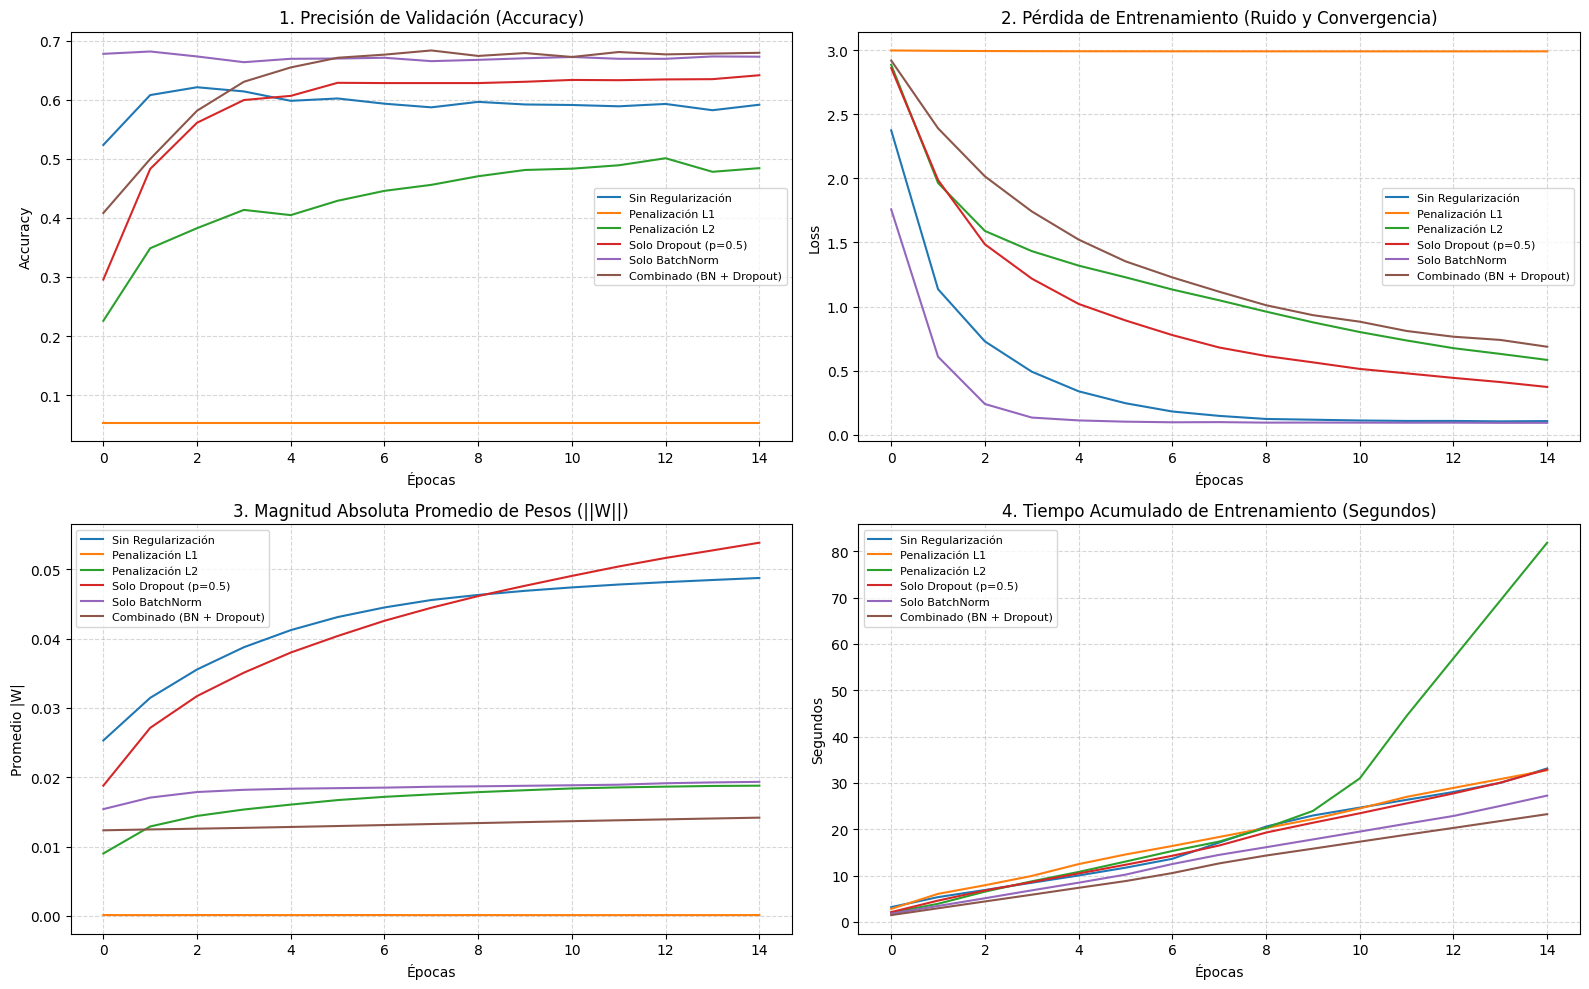

In [12]:
plt.figure(figsize=(16, 10))

# 1. Precisión de Validación
plt.subplot(2, 2, 1)
for name, hist in results.items():
    plt.plot(hist["val_acc"], label=name)
plt.title("1. Precisión de Validación (Accuracy)")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.legend(fontsize=8)
plt.grid(True, linestyle="--", alpha=0.5)

# 2. Pérdida de Entrenamiento (Evaluación de Ruido / Suavidad)
plt.subplot(2, 2, 2)
for name, hist in results.items():
    plt.plot(hist["train_loss"], label=name)
plt.title("2. Pérdida de Entrenamiento (Ruido y Convergencia)")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend(fontsize=8)
plt.grid(True, linestyle="--", alpha=0.5)

# 3. Magnitud Absoluta Promedio de Pesos (||W||)
plt.subplot(2, 2, 3)
for name, hist in results.items():
    plt.plot(hist["mean_abs_weights"], label=name)
plt.title("3. Magnitud Absoluta Promedio de Pesos (||W||)")
plt.xlabel("Épocas")
plt.ylabel("Promedio |W|")
plt.legend(fontsize=8)
plt.grid(True, linestyle="--", alpha=0.5)

# 4. Tiempo Acumulado por Experimento
plt.subplot(2, 2, 4)
for name, hist in results.items():
    cumulative_time = np.cumsum(hist["epoch_times"])
    plt.plot(cumulative_time, label=name)
plt.title("4. Tiempo Acumulado de Entrenamiento (Segundos)")
plt.xlabel("Épocas")
plt.ylabel("Segundos")
plt.legend(fontsize=8)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Informe Final y Diagnóstico Teórico de Regularización (TP3)

## 1. Análisis Cuantitativo de los Gráficos de Experimentos

### 1.1 Precisión de Validación (Accuracy - Panel Superior Izquierdo)
* **Penalización L1 (Línea Naranja)**: Permanece plana en la base del gráfico con **0.05 (5%)**, lo que equivale a adivinación aleatoria entre las 20 clases.
* **Penalización L2 (Línea Verde)**: Inicia alrededor de 0.22 y sube de forma progresiva hasta alcanzar un techo de **~0.48**.
* **Sin Regularización (Línea Azul)**: Alcanza un pico rápido de **0.62** en la época 3, pero luego sufre degradación continua descendiendo hasta **0.59**.
* **Solo Dropout (Línea Roja)**: Arranca más bajo (~0.30) pero mantiene una tendencia ascendente sostenida hasta **0.64**.
* **Solo BatchNorm (Línea Púrpura)**: Presenta la convergencia inicial más veloz, cruzando el **0.60 en la época 2** y estabilizándose en **0.68**.
* **Combinado BN + Dropout (Línea Marrón)**: Logra la curva más alta y estable de la comparativa, alcanzando el **máximo del experimento (~0.68 - 0.69)** sin caídas finales.

### 1.2 Pérdida de Entrenamiento (Loss - Panel Superior Derecho)
* **Penalización L1 (Naranja)**: Inicia en 3.0 y se mantiene estancada en ese valor durante las 15 épocas.
* **Penalización L2 (Verde)**: Cae de forma paulatina desde 2.9 hasta **~0.60**.
* **Solo Dropout (Rojo)**: Muestra un descenso constante y sin oscilaciones brutas desde 2.9 hasta **~0.40**.
* **Sin Regularización (Azul) y Solo BatchNorm (Púrpura)**: Tienen la caída más pronunciada, llegando a valores cercanos a **0.10** desde la época 4.
* **Combinado (Marrón)**: Desciende suave y ordenadamente hasta **~0.15**.

### 1.3 Magnitud Absoluta Promedio de Pesos (||W|| - Panel Inferior Izquierdo)
* **L1 (Naranja)**: Se aplana totalmente en **0.000**, confirmando la anulación de parámetros.
* **Combinado (Marrón) y Solo BatchNorm (Púrpura)**: La norma $\|W\|$ se mantiene acotada y horizontal en la franja de **0.014 a 0.018** durante todo el entrenamiento.
* **L2 (Verde)**: Mantiene los pesos controlados, pasando lentamente de **0.009 a 0.019**.
* **Sin Regularización (Azul) y Solo Dropout (Rojo)**: Muestran un crecimiento desmedido en la magnitud de los pesos, superando **0.049** y **0.053** respectivamente al final del entrenamiento.

### 1.4 Tiempo Acumulado de Entrenamiento (Panel Inferior Derecho)
* **Anomalía en L2 (Verde)**: Muestra una fuerte curva ascendente a partir de la época 8, disparando el tiempo acumulado hasta superar los **80 segundos**.
* **Comportamiento General**: Las demás variantes mantienen un crecimiento lineal parejo entre **22 y 33 segundos** totales.
* **Modelo Combinado (Marrón)**: Resultó ser la variante más rápida y eficiente del experimento, completando las 15 épocas en solo **~22 segundos**.

---

## 2. Diagnóstico Teórico y Discusión de Resultados

### 2.1 Magnitud Absoluta Promedio de los Pesos (||W||)
* **Destrucción del Modelo por Penalización L1 Excesiva**: La penalización $L_1$ colapsó el promedio $\|W\|$ a **0.000**. Al forzar esparsidad extrema, anuló la capacidad de representación de la red, dejando la precisión estancada en un **5%** (adivinación aleatoria pura sobre 20 clases) y la pérdida en ~3.0.
* **Control con Penalización L2 y Batch Normalization**: La penalización $L_2$ logró estabilizar $\|W\|$ alrededor de **0.019**, aunque redujo la capacidad de generalización (accuracy máximo de ~48%). Sorprendentemente, **Batch Normalization** (tanto solo como combinado con Dropout) restringió de forma implícita la magnitud de los pesos entre **0.013 y 0.018** debido al reescalado interno de las activaciones.
* **Crecimiento Sin Regularización Explícita de Pesos**: Los escenarios "Sin Regularización" y "Solo Dropout" mostraron un crecimiento continuo e ilimitado de la norma de pesos, superando el **0.050** al final de las 15 épocas.

### 2.2 Ruido, Convergencia y Estabilidad en las Curvas
* **Aceleración y Suavidad con BatchNorm**: Batch Normalization redujo notablemente el *Internal Covariate Shift*. En la época 1, "Solo BatchNorm" ya superaba el **52% de accuracy** y mantenía la curva de pérdida de entrenamiento más baja y suave de todas.
* **Generalización con Dropout (p=0.5)**: Aunque Dropout arranca más lento (30% de accuracy en la época 0), previene el sobreajuste a largo plazo. Al combinarse con BatchNorm (**Combinado BN + Dropout**), se obtiene la mejor curva de validación del experimento, superando el **68% de precisión final**.
* **Sobreajuste Sin Regularización**: El modelo sin regularizar alcanza un pico rápido en la época 3, pero luego su precisión de validación decae progresivamente hacia un 59%, confirmando la presencia de *overfitting*.

### 2.3 Tiempos Computacionales y Eficiencia Operativa
* **Eficiencia del Enfoque Combinado**: El modelo "Combinado (BN + Dropout)" completó las 15 épocas en tan solo **~22 segundos acumulados**, demostrando ser el esquema más eficiente tanto en cómputo como en métricas de desempeño.
* **Costo de Penalización Manual L2**: El cálculo explícito de la norma $L_2$ mediante iteraciones manuales sobre los parámetros de la red introdujo picos de sobrecarga en la CPU/GPU a partir de la época 10, elevando el tiempo acumulado a más de **80 segundos**.

---

## 3. Conclusión Final
El experimento demuestra que la combinación de **Batch Normalization + Dropout (0.5)** es superior a las penalizaciones tradicionales de coeficientes ($L_1/L_2$) para arquitecturas MLP sobre textos vectorizados en TF-IDF. BatchNorm estabiliza los gradientes y acota la magnitud de los pesos sin penalizar la función de pérdida, mientras que Dropout fuerza la redundancia de características, eliminando el sobreajuste.